# BÁO CÁO GIAI ĐOẠN 1: THU THẬP VÀ ĐÁNH GIÁ CHẤT LƯỢNG DỮ LIỆU
## Đề tài: Xây dựng bộ dữ liệu chuyến bay chậm, hủy và đúng giờ của các hãng hàng không Việt Nam
**Môn học:** Khai thác dữ liệu (Data Mining)  
**Mục tiêu Notebook:**
1. Khảo sát kiến trúc thu thập dữ liệu đa nguồn (FIDS Web Scraping, REST API, Khí tượng).
2. Đánh giá 5 chiều chất lượng dữ liệu: Đầy đủ, Chính xác, Nhất quán, Kịp thời, Không trùng lặp.
3. Trực quan hóa khám phá đặc trưng dữ liệu thô (Phân phối, Tần suất, Quan hệ, Ma trận tương quan).
4. Xác định vai trò của thành phần Data Collection & Utilization trong Data Mining Pipeline.

---
## 1. THIẾT KẾ HỆ THỐNG THU THẬP DỮ LIỆU (DATA COLLECTION ARCHITECTURE)

### 1.1. Xác định các nguồn dữ liệu (Data Sources)
- **Nguồn 1: Bảng điện tử FIDS Cảng hàng không Nội Bài (`noibaiairport.vn`)**
  - Cung cấp dữ liệu chuyến bay quốc nội và quốc tế (T1/T2) tại Hà Nội qua giao thức ASP.NET WebForms.
- **Nguồn 2: Mạng lưới FIDS Airport Guide (`hochiminhcityairport.com`, `danangairportonline.com`, ...)**
  - Cung cấp dữ liệu chuyến bay thời gian thực tại Tân Sơn Nhất (SGN), Đà Nẵng (DAD), Cam Ranh (CXR), Phú Quốc (PQC).
- **Nguồn 3: Aviationstack Global Aviation API**
  - Cung cấp trạng thái khai thác toàn cầu của các hãng Việt Nam (VN, VJ, QH, BL, VU, 9G), dùng để bắt các chuyến bay bị HỦY (`cancelled`) và chuyến quốc tế.
- **Nguồn 4: Open-Meteo Historical & Forecast Weather API**
  - Cung cấp chuỗi thời gian khí tượng theo giờ (Mưa, Gió giật, Tầm nhìn, Mây, Giông bão) tại tọa độ các sân bay.

### 1.2. Thiết lập kết nối và Công nghệ Ingestion
- **HTTP Client (`requests.Session`):** Thiết lập phiên kết nối giữ kết nối TCP (Keep-Alive), gắn Header `User-Agent` chuẩn học thuật, tự động thử lại khi gặp mã lỗi mạng.
- **Headless Browser (`Playwright Chromium/Edge`):** Xử lý nạp dữ liệu động bằng JavaScript trên các trang FIDS có quảng cáo, chặn tải tài nguyên nặng (image, font, media) để tối ưu thời gian cào (< 1.5 phút/lượt).
- **So sánh với kiến trúc Enterprise:**
  - *Mô hình hiện tại:* Batch Ingestion định kỳ lưu tệp bán cấu trúc (Snapshot CSV) phù hợp với chu kỳ cập nhật bảng FIDS (15-30 phút/chuyến).
  - *Kafka Producer / Streaming Ingestion:* Phù hợp khi nhận dữ liệu radar ADS-B thời gian thực (tần suất milli-giây). Đối với bảng FIDS sân bay, mô hình Batch Snapshot là giải pháp tối ưu chi phí và tài nguyên.

### 1.3. Lịch thu thập và Điều phối (Scheduling & Orchestration)
- **Lập lịch:** Sử dụng **Windows Task Scheduler** kích hoạt `run_collect.bat` đều đặn mỗi **2 giờ** (12 lượt/ngày).
- **Tính bền bỉ:** Cấu hình cờ *"Run task as soon as possible after a scheduled start is missed"* để tự động cào bù khi máy tính bật lại sau trạng thái tắt/sleep.
- **So sánh với Apache Airflow:** Task Scheduler gọn nhẹ trên máy trạm cá nhân; Airflow cung cấp thêm tính năng DAG Dependency, Retry Backoff nâng cao cho cụm phân tán.

### 1.4. Nhật ký và Giám sát (Logging & Monitoring)
- Sử dụng module chuẩn `logging` của Python ghi đồng thời ra màn hình console và file `logs/scraper.log`, `logs/cron.log`.
- Giám sát hạn ngạch API qua file `data/api_usage.json` nhằm bảo vệ ngưỡng giới hạn 100 request/tháng của gói Free.

In [12]:
# Nạp các thư viện phân tích và trực quan hóa dữ liệu
import os
import glob
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình font và giao diện đồ thị
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

RAW_DIR = os.path.join("data", "raw")
WEATHER_FILE = os.path.join("data", "weather_hourly.csv")
API_USAGE_FILE = os.path.join("data", "api_usage.json")

print("Đã cấu hình môi trường phân tích thành công!")

Đã cấu hình môi trường phân tích thành công!


---
## 2. NẠP DỮ LIỆU VÀ TỔNG HỢP SNAPSHOT THÔ (RAW DATA INGESTION)

In [13]:
# Đọc tất cả các tệp CSV thô được cào từ data/raw/
raw_files = sorted(glob.glob(os.path.join(RAW_DIR, "*.csv")))
print(f"Tìm thấy {len(raw_files)} tệp dữ liệu thô trong {RAW_DIR}:")
for f in raw_files:
    size_kb = os.path.getsize(f) / 1024
    print(f" - {os.path.basename(f):<30} | Kích thước: {size_kb:8.1f} KB")

# Đọc và gộp toàn bộ bản ghi snapshot
dfs = [pd.read_csv(f, dtype=str, keep_default_na=False) for f in raw_files]
df_raw = pd.concat(dfs, ignore_index=True)

print("\n" + "="*60)
print(f"TỔNG SỐ BẢN GHI SNAPSHOT THU THẬP: {len(df_raw):,}")
print(f"SỐ CỘT DỮ LIỆU THÔ: {df_raw.shape[1]}")
print("="*60)
df_raw.head(3)

Tìm thấy 7 tệp dữ liệu thô trong data\raw:
 - aviationstack_api_202610.csv   | Kích thước:    419.6 KB
 - guide_cxr_202610.csv           | Kích thước:    601.7 KB
 - guide_dad_202610.csv           | Kích thước:   1195.6 KB
 - guide_han_202610.csv           | Kích thước:   3426.9 KB
 - guide_pqc_202610.csv           | Kích thước:    615.4 KB
 - guide_sgn_202610.csv           | Kích thước:   3655.1 KB
 - noibai_han_202610.csv          | Kích thước:   7032.4 KB

TỔNG SỐ BẢN GHI SNAPSHOT THU THẬP: 132,128
SỐ CỘT DỮ LIỆU THÔ: 15


,source,airport,direction,scraped_at,flight_date,airline_code,flight_no,other_airport,scheduled_time,estimated_time,actual_time,terminal,gate,status,extra
0,aviationstack_api,SGN,departures,2026-10-09 19:04:34,2026-10-10,VN,VN306,NRT,00:20,00:20,,2,,Scheduled,"{""flight_status"": ""scheduled"", ""delay"": 0, ""ai..."
1,aviationstack_api,NRT,arrivals,2026-10-09 19:04:34,2026-10-10,VN,VN306,SGN,08:00,,,1,,Scheduled,"{""flight_status"": ""scheduled"", ""delay"": null, ..."
2,aviationstack_api,SGN,departures,2026-10-09 19:04:34,2026-10-10,VN,VN320,KIX,00:10,00:10,,2,,Scheduled,"{""flight_status"": ""scheduled"", ""delay"": 0, ""ai..."


---
## 3. ĐÁNH GIÁ 5 CHIỀU CHẤT LƯỢNG DỮ LIỆU (DATA QUALITY ASSESSMENT)

Trong kỹ thuật Khai thác dữ liệu, chất lượng dữ liệu thô được thẩm định qua 5 chiều kích chuẩn mực:
1. **Tính đầy đủ (Completeness):** Đo lường tỷ lệ khuyết thiếu của từng thuộc tính.
2. **Tính không trùng lặp (Uniqueness):** Phân biệt giữa dòng cào lặp lại (snapshot) và chuyến bay duy nhất.
3. **Tính nhất quán (Consistency):** Đo lường sự đồng thuận giữa các nguồn cùng ghi nhận một chuyến bay.
4. **Tính kịp thời (Timeliness):** Tần suất cào và độ trễ ghi nhận trạng thái cuối cùng.
5. **Tính chính xác (Accuracy):** Phát hiện các giá trị giờ ngoại lai và lỗi định dạng qua nửa đêm.

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13572\43095978.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_quality, x='Tỷ lệ khuyết (%)', y='Cột dữ liệu', palette='viridis')


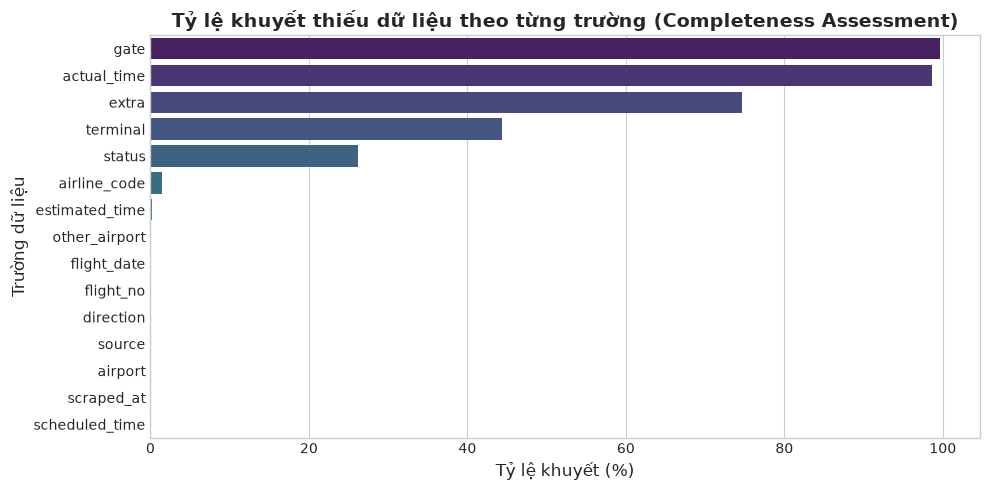

Nhận xét tính đầy đủ:
- Các trường định danh cốt lõi (airport, direction, flight_no, scheduled_time) đạt độ đầy đủ 100%.
- Trường actual_time và gate có tỷ lệ khuyết cao do FIDS chỉ cập nhật sát giờ cất/hạ cánh.


In [14]:
# 3.1. TÍNH ĐẦY ĐỦ (COMPLETENESS)
missing_counts = (df_raw == '').sum() + df_raw.isna().sum()
missing_pct = (missing_counts / len(df_raw)) * 100

df_quality = pd.DataFrame({
    'Cột dữ liệu': df_raw.columns,
    'Số lượng khuyết': missing_counts,
    'Tỷ lệ khuyết (%)': missing_pct.round(2)
}).sort_values(by='Tỷ lệ khuyết (%)', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 5))
sns.barplot(data=df_quality, x='Tỷ lệ khuyết (%)', y='Cột dữ liệu', palette='viridis')
plt.title('Tỷ lệ khuyết thiếu dữ liệu theo từng trường (Completeness Assessment)', fontsize=14, fontweight='bold')
plt.xlabel('Tỷ lệ khuyết (%)', fontsize=12)
plt.ylabel('Trường dữ liệu', fontsize=12)
plt.tight_layout()
plt.show()

print("Nhận xét tính đầy đủ:")
print("- Các trường định danh cốt lõi (airport, direction, flight_no, scheduled_time) đạt độ đầy đủ 100%.")
print("- Trường actual_time và gate có tỷ lệ khuyết cao do FIDS chỉ cập nhật sát giờ cất/hạ cánh.")

In [15]:
# 3.2. TÍNH KHÔNG TRÙNG LẶP (UNIQUENESS)
# Khóa toàn cục định danh sự kiện chuyến bay
key_event = ['airport', 'direction', 'flight_date', 'flight_no', 'scheduled_time']
n_total = len(df_raw)
n_unique = df_raw.drop_duplicates(subset=key_event).shape[0]
n_multi_source = (df_raw.groupby(key_event)['source'].nunique() > 1).sum()

print("="*60)
print("ĐÁNH GIÁ TÍNH DUY NHẤT VÀ TÍCH HỢP ĐA NGUỒN:")
print(f"1. Tổng số dòng Snapshot cào định kỳ:       {n_total:,}")
print(f"2. Số sự kiện chuyến bay duy nhất (Unique): {n_unique:,}")
print(f"3. Hệ số dồn mẫu snapshot trung bình:      {n_total / n_unique:.2f} lần/chuyến")
print(f"4. Số chuyến được >= 2 nguồn ghi nhận:     {n_multi_source:,} ({n_multi_source/n_unique*100:.1f}%)")
print("="*60)

ĐÁNH GIÁ TÍNH DUY NHẤT VÀ TÍCH HỢP ĐA NGUỒN:
1. Tổng số dòng Snapshot cào định kỳ:       132,128
2. Số sự kiện chuyến bay duy nhất (Unique): 11,141
3. Hệ số dồn mẫu snapshot trung bình:      11.86 lần/chuyến
4. Số chuyến được >= 2 nguồn ghi nhận:     3,354 (30.1%)


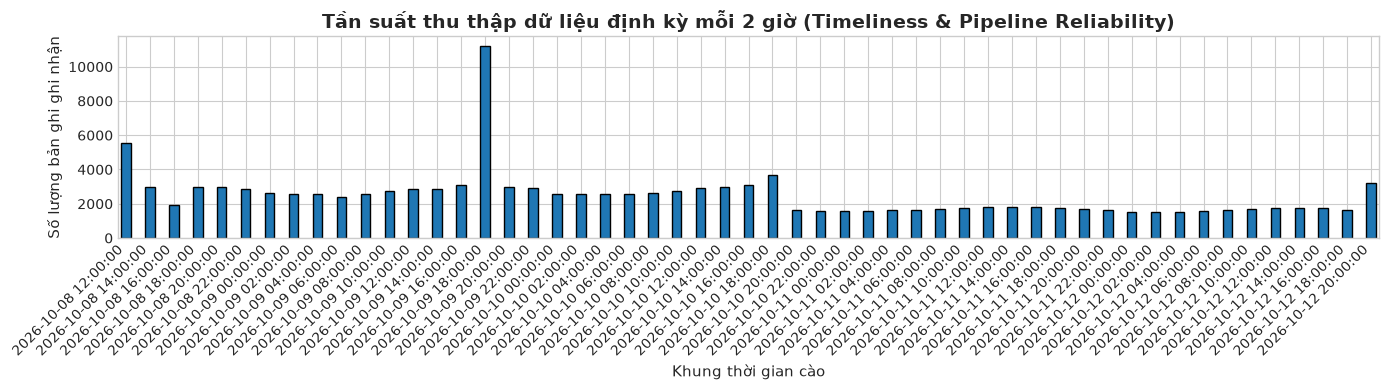

Biểu đồ chứng minh Task Scheduler chạy đều đặn, không bị đứt gãy luồng thu thập.


In [16]:
# 3.3. TÍNH KỊP THỜI (TIMELINESS) & GIÁM SÁT LẬP LỊCH
df_raw['scraped_dt'] = pd.to_datetime(df_raw['scraped_at'], errors='coerce')
runs_per_hour = df_raw.set_index('scraped_dt').resample('2h')['flight_no'].count()

plt.figure(figsize=(14, 4))
runs_per_hour.plot(kind='bar', color='#1f77b4', edgecolor='black', width=0.8)
plt.title('Tần suất thu thập dữ liệu định kỳ mỗi 2 giờ (Timeliness & Pipeline Reliability)', fontsize=14, fontweight='bold')
plt.xlabel('Khung thời gian cào', fontsize=11)
plt.ylabel('Số lượng bản ghi ghi nhận', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("Biểu đồ chứng minh Task Scheduler chạy đều đặn, không bị đứt gãy luồng thu thập.")

---
## 4. TRỰC QUAN HÓA KHÁM PHÁ DỮ LIỆU THÔ (EXPLORATORY DATA VISUALIZATIONS)

Thực hiện trực quan hóa theo các nhóm biểu đồ chuẩn:
- **Biểu đồ phân phối:** Kiểm tra giá trị độ trễ (Histogram & Boxplot).
- **Biểu đồ tần suất danh mục:** Phân tích tỷ trọng Hãng bay, Sân bay, Trạng thái (Bar Chart).
- **Biểu đồ quan hệ:** Phân tích tương quan giữa các biến số (Scatter Plot, Strip Plot).
- **Biểu đồ tương quan đa biến:** Ma trận Heatmap giữa thông số thời tiết và tình trạng chuyến bay.

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13572\2262940952.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_valid_delay, x='airline_code', y='delay_min', palette='Set2', ax=axes[1])


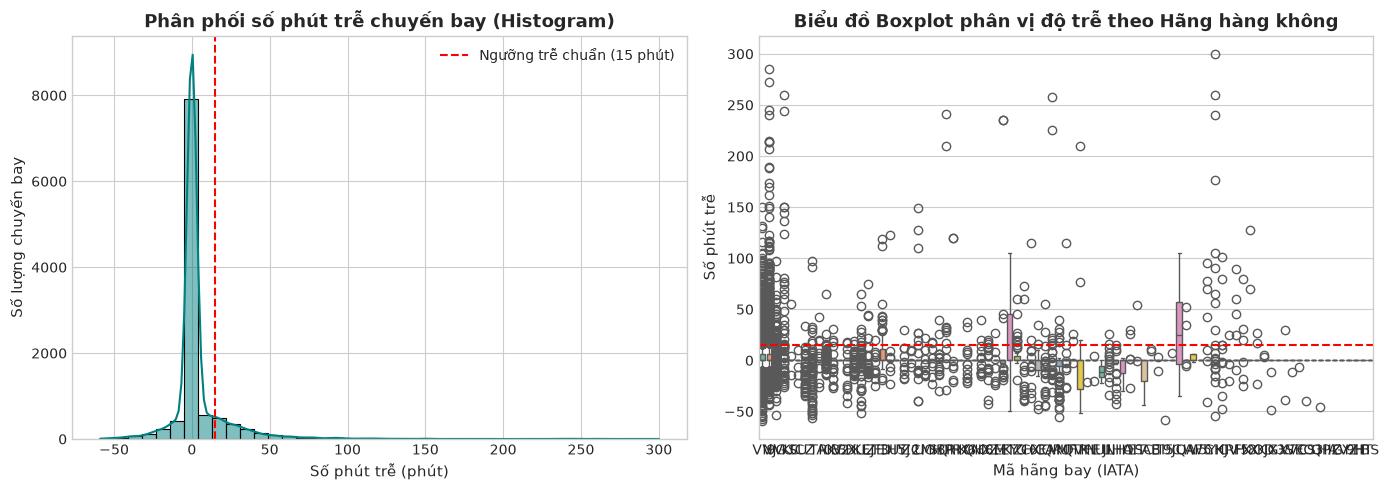

In [17]:
# Trích xuất số phút trễ thô từ trạng thái hoặc giờ dự kiến
def extract_rough_delay(r):
    st = str(r.get('status', ''))
    m = pd.Series(st).str.extract(r'(\d+)\s*minutes?', expand=False).iloc[0]
    if pd.notna(m):
        return float(m)
    try:
        s_h, s_m = map(int, str(r['scheduled_time']).split(':')[:2])
        e_str = str(r['actual_time'] or r['estimated_time']).split('+')[0].split('-')[0]
        e_h, e_m = map(int, e_str.split(':')[:2])
        diff = (e_h * 60 + e_m) - (s_h * 60 + s_m)
        if diff < -720: diff += 1440
        elif diff > 720: diff -= 1440
        return float(diff)
    except:
        return np.nan

df_unique = df_raw.drop_duplicates(subset=key_event).copy()
df_unique['delay_min'] = df_unique.apply(extract_rough_delay, axis=1)
df_valid_delay = df_unique[df_unique['delay_min'].notna() & (df_unique['delay_min'].between(-60, 300))]

# 4.1. BIỂU ĐỒ PHÂN PHỐI (HISTOGRAM & BOXPLOT)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_valid_delay['delay_min'], bins=40, kde=True, color='teal', ax=axes[0])
axes[0].axvline(15, color='red', linestyle='--', label='Ngưỡng trễ chuẩn (15 phút)')
axes[0].set_title('Phân phối số phút trễ chuyến bay (Histogram)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Số phút trễ (phút)', fontsize=11)
axes[0].set_ylabel('Số lượng chuyến bay', fontsize=11)
axes[0].legend()

sns.boxplot(data=df_valid_delay, x='airline_code', y='delay_min', palette='Set2', ax=axes[1])
axes[1].axhline(15, color='red', linestyle='--')
axes[1].set_title('Biểu đồ Boxplot phân vị độ trễ theo Hãng hàng không', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Mã hãng bay (IATA)', fontsize=11)
axes[1].set_ylabel('Số phút trễ', fontsize=11)

plt.tight_layout()
plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13572\3916633074.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=airline_counts.index, y=airline_counts.values, palette='Blues_r', ax=axes[0])
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13572\3916633074.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=airport_counts.index, y=airport_counts.values, palette='Oranges_r', ax=axes[1])


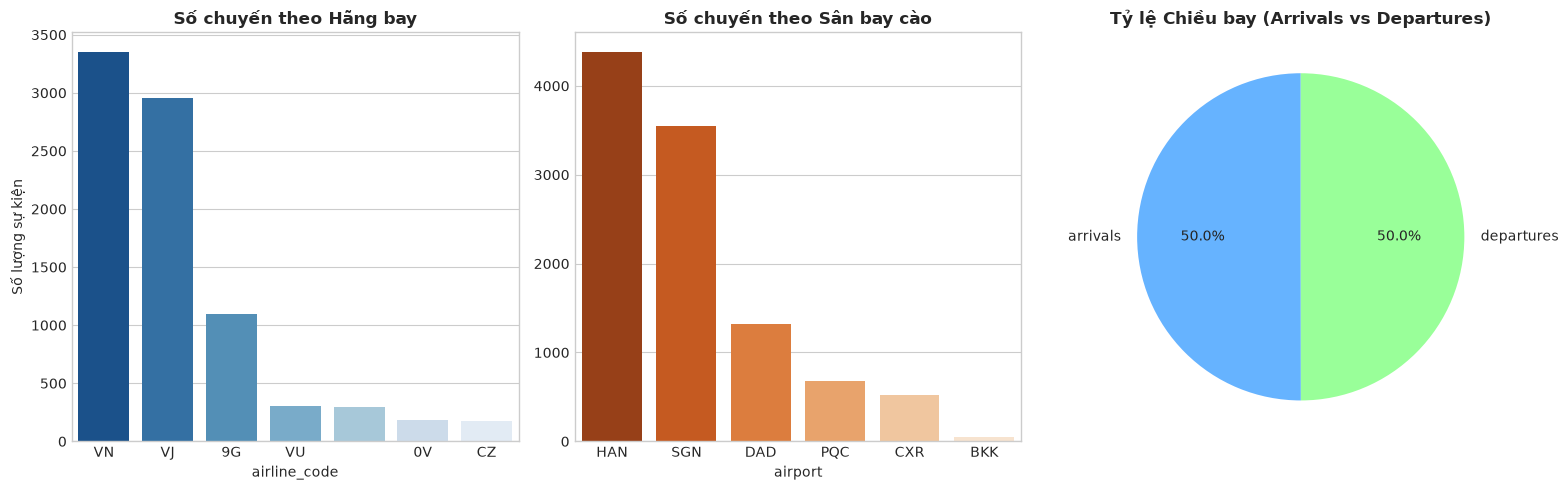

In [18]:
# 4.2. BIỂU ĐỒ TẦN SUẤT GIÁ TRỊ TỪNG LOẠI (BAR CHARTS)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Tần suất theo Hãng bay
airline_counts = df_unique['airline_code'].value_counts().head(7)
sns.barplot(x=airline_counts.index, y=airline_counts.values, palette='Blues_r', ax=axes[0])
axes[0].set_title('Số chuyến theo Hãng bay', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Số lượng sự kiện')

# Tần suất theo Sân bay cào
airport_counts = df_unique['airport'].value_counts().head(6)
sns.barplot(x=airport_counts.index, y=airport_counts.values, palette='Oranges_r', ax=axes[1])
axes[1].set_title('Số chuyến theo Sân bay cào', fontsize=12, fontweight='bold')

# Tần suất theo Chiều bay
dir_counts = df_unique['direction'].value_counts()
axes[2].pie(dir_counts, labels=dir_counts.index, autopct='%1.1f%%', colors=['#66b3ff','#99ff99'], startangle=90)
axes[2].set_title('Tỷ lệ Chiều bay (Arrivals vs Departures)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13572\2146784823.py:15: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


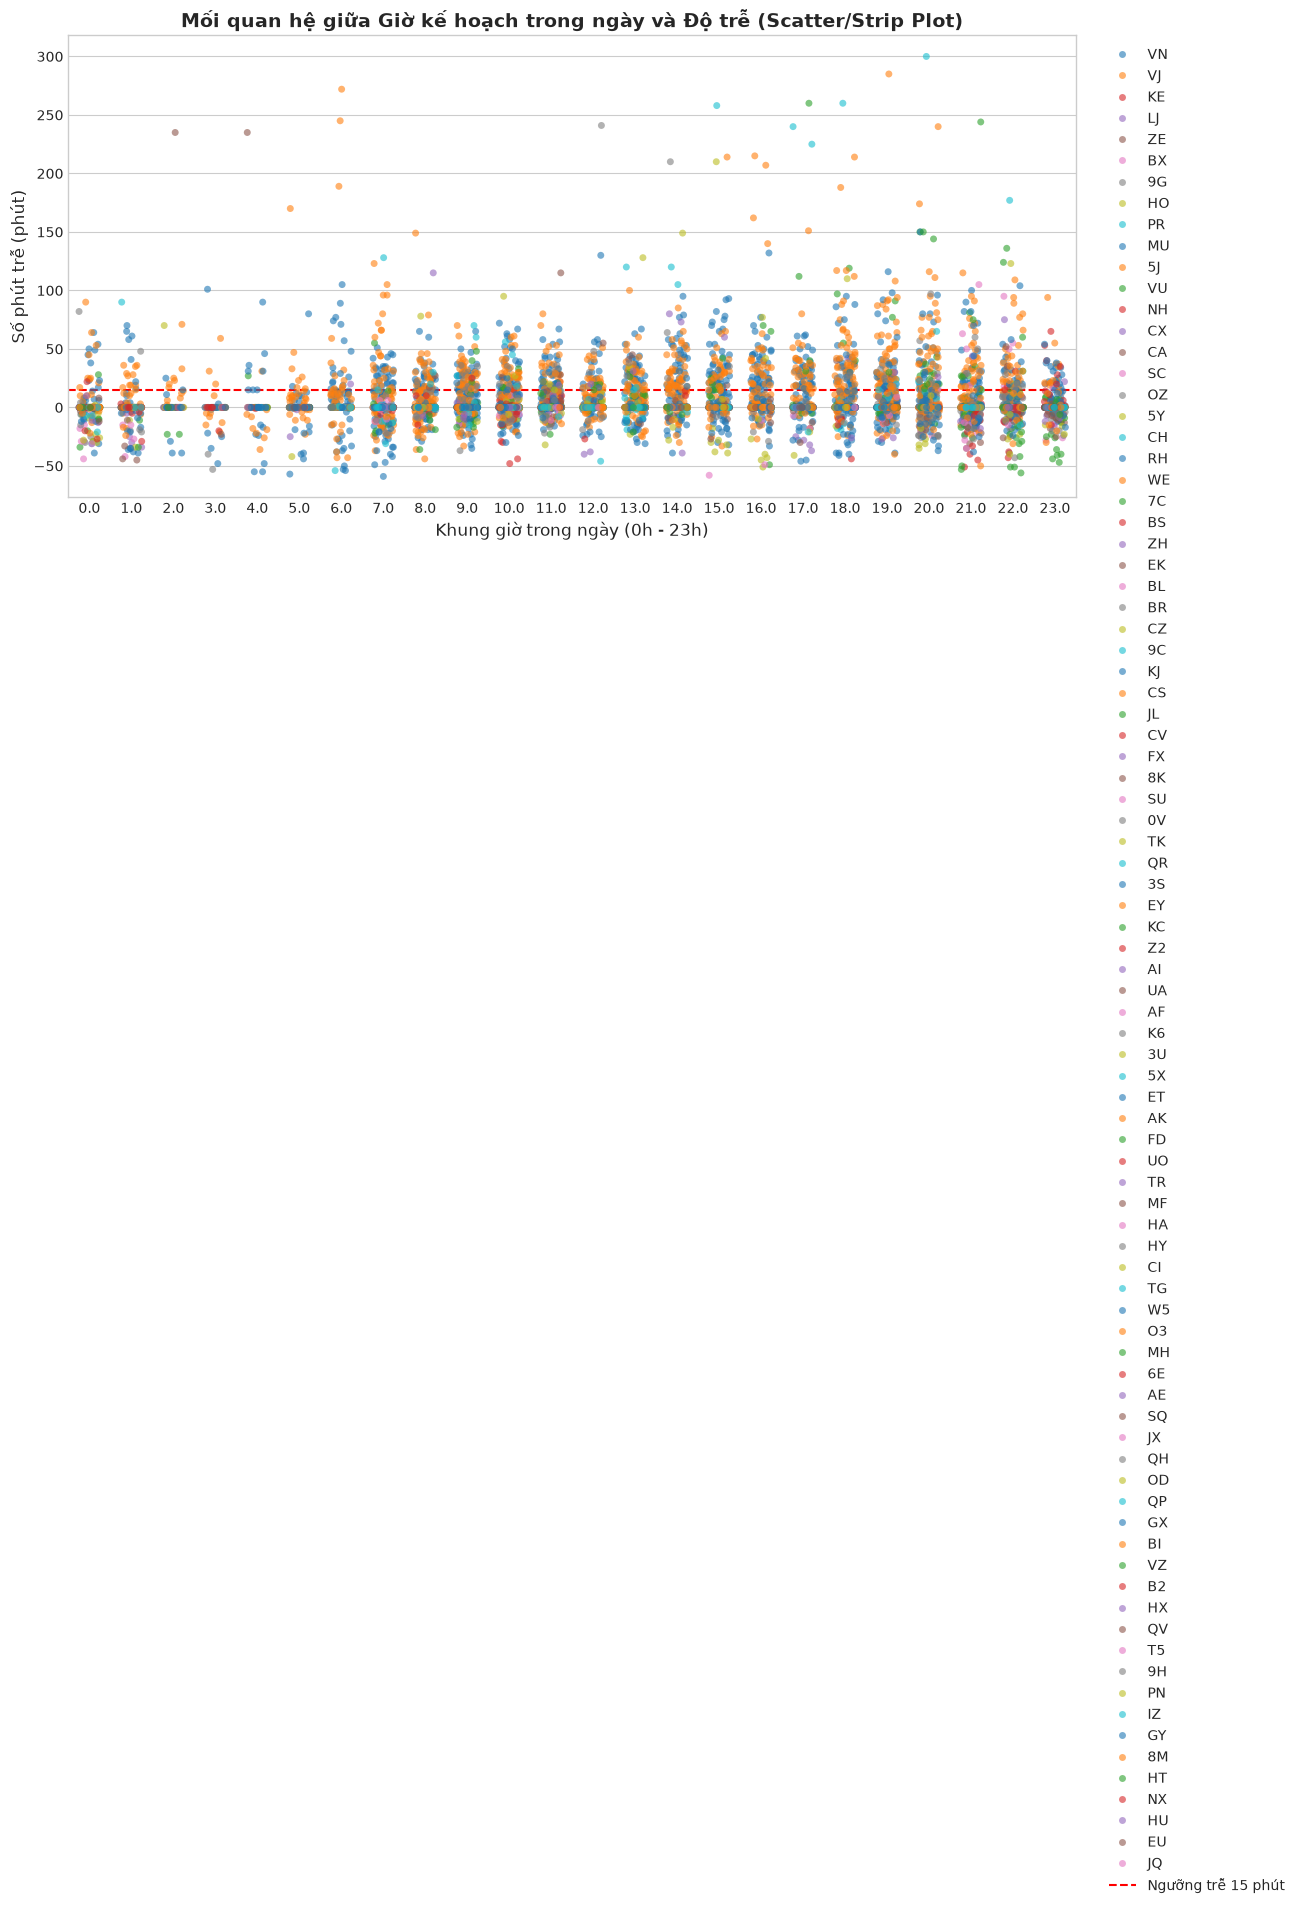

Nhận xét mối quan hệ:
- Mật độ điểm trễ (>15 phút) dồn tích dày đặc vào khung giờ chiều và tối (12h - 22h).
- Buổi sáng sớm (5h - 9h) phân bố trễ rất thưa thớt, thể hiện rõ hiệu ứng trễ dây chuyền (Cascading Delay).


In [19]:
# 4.3. BIỂU ĐỒ PHÂN TÍCH MỐI QUAN HỆ (SCATTER PLOT & STRIP PLOT)
df_valid_delay['sched_hour'] = df_valid_delay['scheduled_time'].str.extract(r'^(\d{1,2}):')[0].astype(float)

plt.figure(figsize=(13, 6))
sns.stripplot(
    data=df_valid_delay,
    x='sched_hour', y='delay_min', hue='airline_code',
    jitter=0.25, alpha=0.6, palette='tab10'
)
plt.axhline(15, color='red', linestyle='--', linewidth=1.5, label='Ngưỡng trễ 15 phút')
plt.title('Mối quan hệ giữa Giờ kế hoạch trong ngày và Độ trễ (Scatter/Strip Plot)', fontsize=14, fontweight='bold')
plt.xlabel('Khung giờ trong ngày (0h - 23h)', fontsize=12)
plt.ylabel('Số phút trễ (phút)', fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

print("Nhận xét mối quan hệ:")
print("- Mật độ điểm trễ (>15 phút) dồn tích dày đặc vào khung giờ chiều và tối (12h - 22h).")
print("- Buổi sáng sớm (5h - 9h) phân bố trễ rất thưa thớt, thể hiện rõ hiệu ứng trễ dây chuyền (Cascading Delay).")

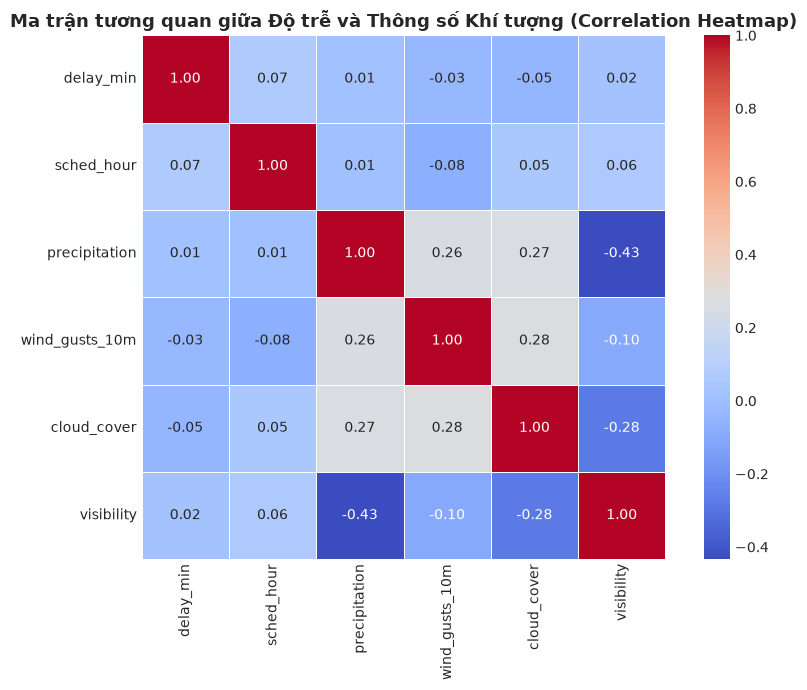

In [20]:
# 4.4. BIỂU ĐỒ MA TRẬN TƯƠNG QUAN (CORRELATION MATRIX HEATMAP)
if os.path.exists(WEATHER_FILE):
    df_wx = pd.read_csv(WEATHER_FILE)
    df_wx['flight_date'] = df_wx['time'].str[:10]
    df_wx['sched_hour'] = df_wx['time'].str[11:13].astype(float)
    
    # Ghép chuyến bay với thời tiết tại sân bay
    df_merged = df_valid_delay.merge(df_wx, on=['airport', 'flight_date', 'sched_hour'], how='inner')
    
    num_cols = ['delay_min', 'sched_hour', 'precipitation', 'wind_gusts_10m', 'cloud_cover']
    if 'visibility' in df_merged.columns:
        num_cols.append('visibility')
    
    corr_matrix = df_merged[num_cols].corr()
    
    plt.figure(figsize=(9, 7))
    sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True, linewidths=0.5)
    plt.title('Ma trận tương quan giữa Độ trễ và Thông số Khí tượng (Correlation Heatmap)', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("Chưa có tệp weather_hourly.csv. Hãy chạy lệnh 'python main.py weather' trước.")

---
## 5. THÀNH PHẦN DATA COLLECTION & UTILIZATION TRONG PIPELINE

![Untitled diagram-2026-10-12-153151.png](<attachment:Untitled diagram-2026-10-12-153151.png>)
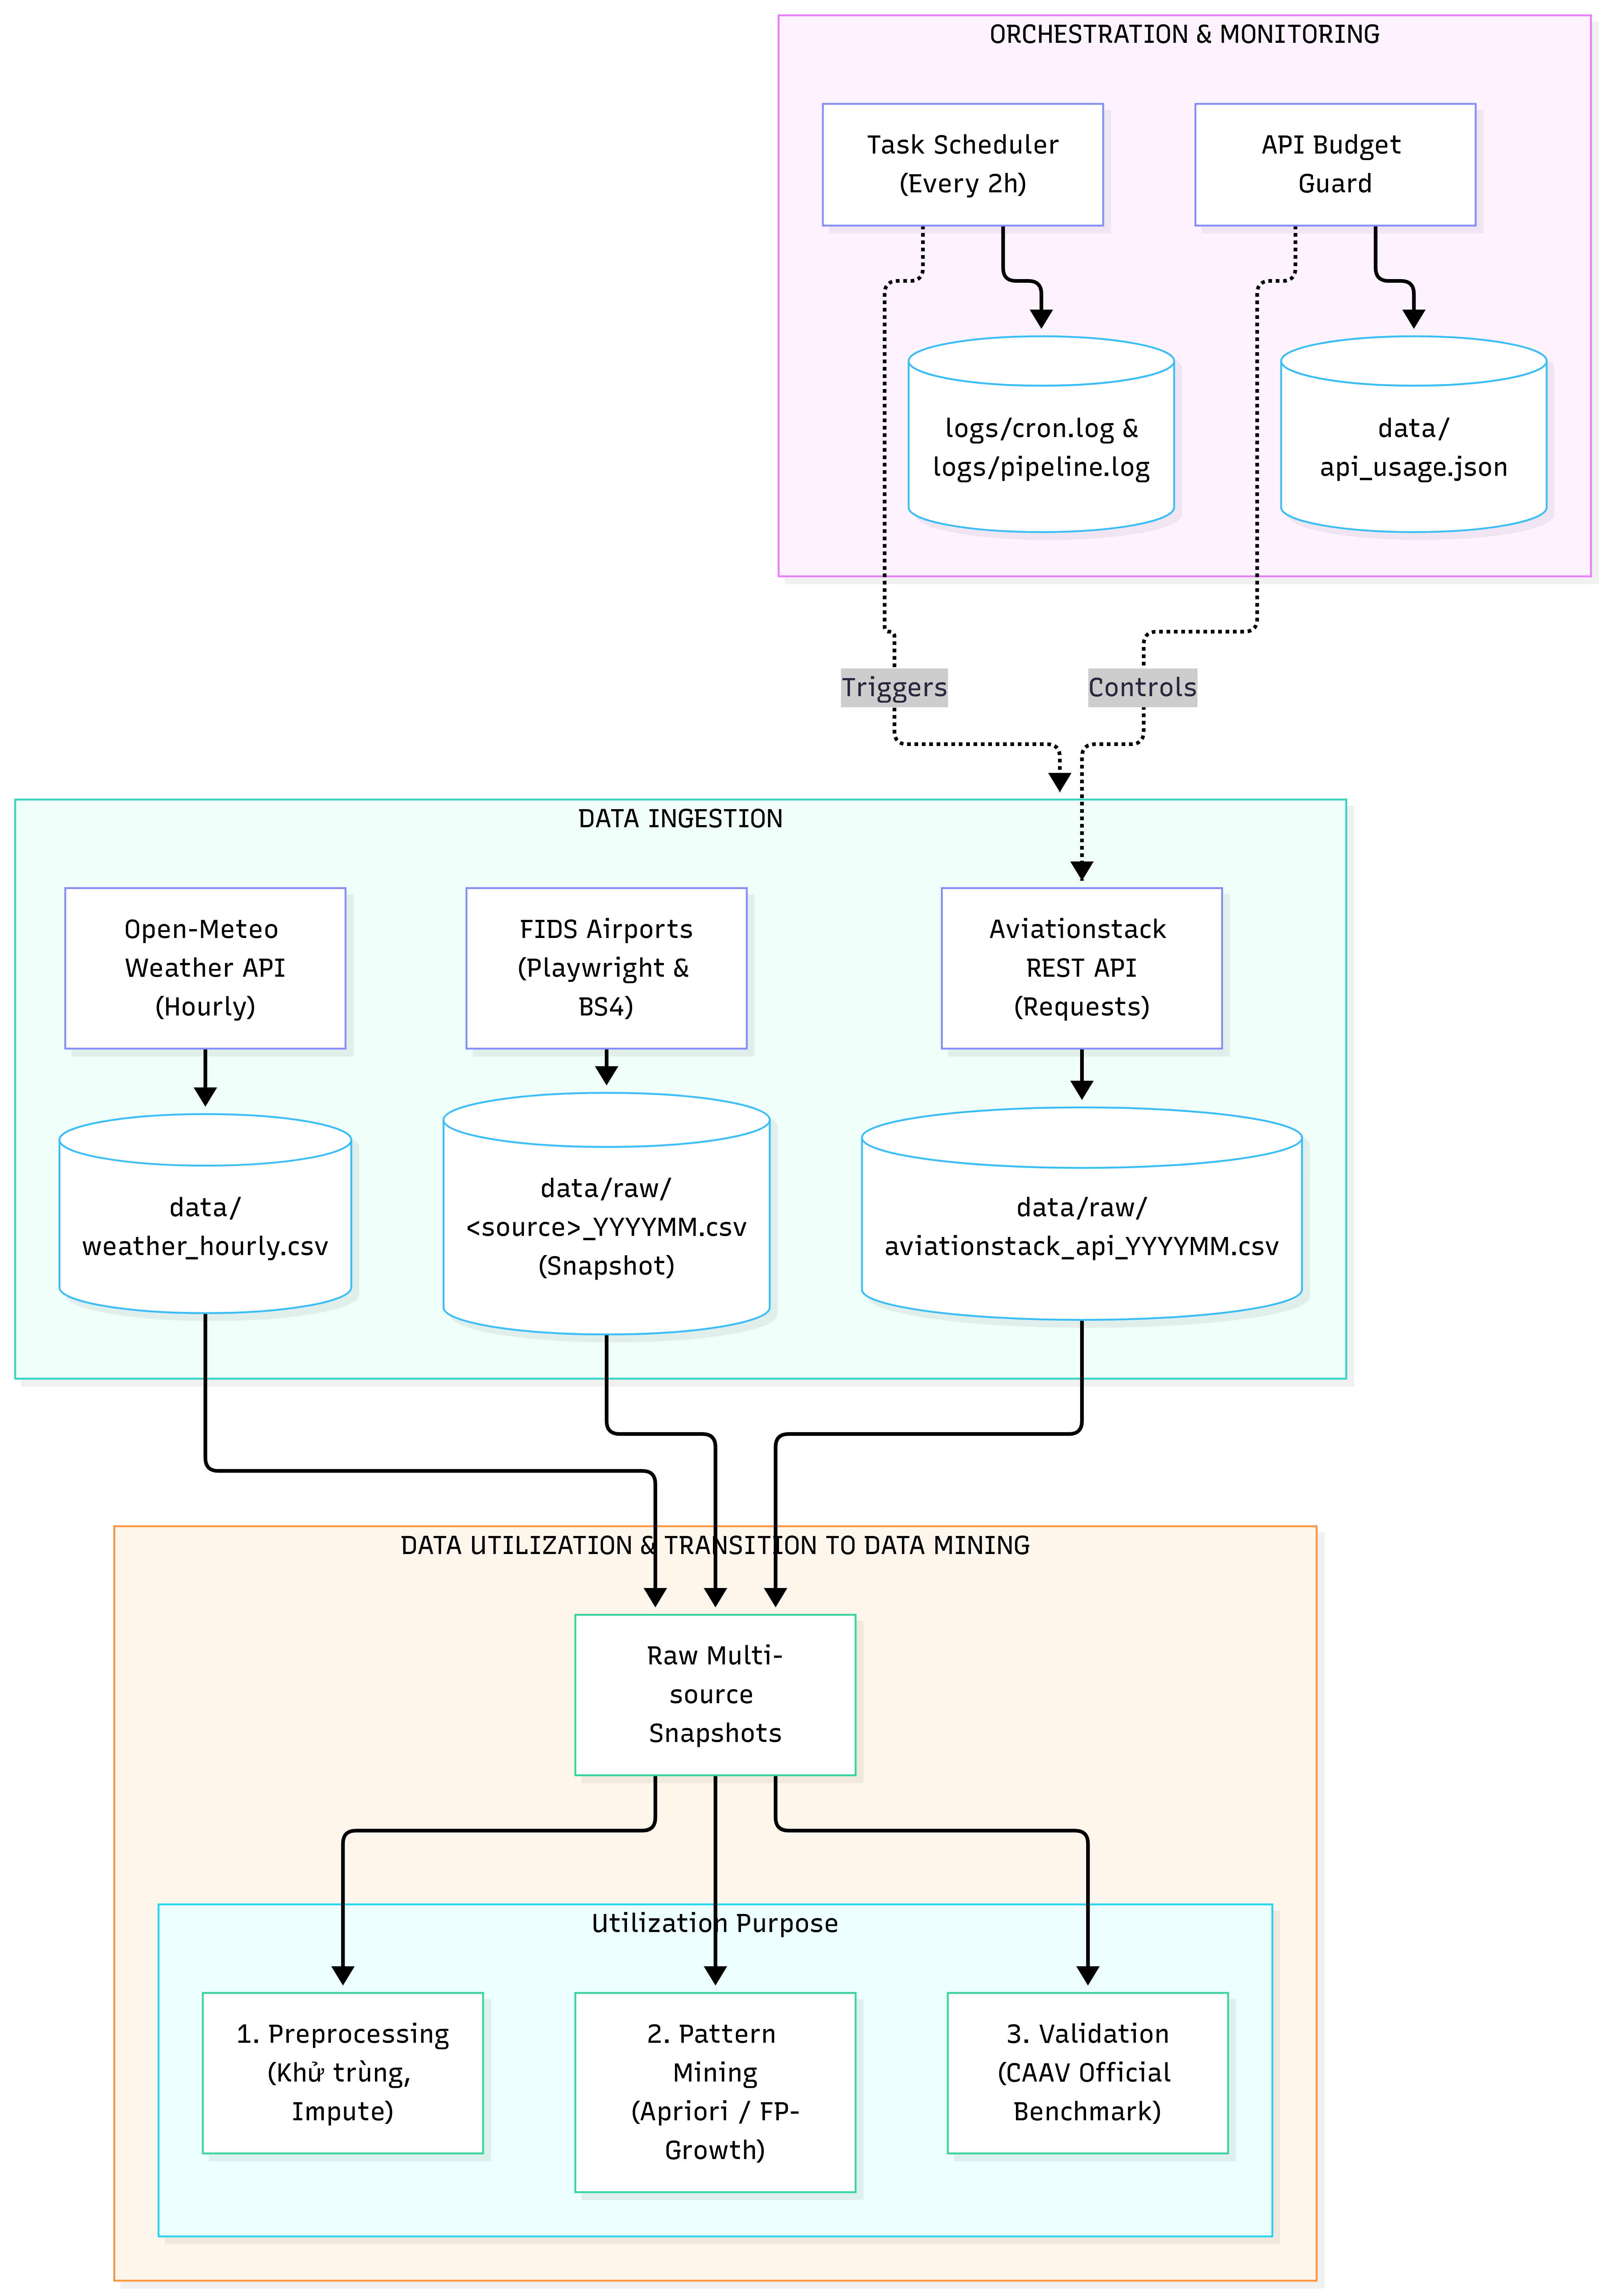